In [1]:

# 1. Import Libraries
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Flatten, Dense

In [2]:
# 2. Load Dataset from Local System
path = r"C:\Users\Vaishnavi\Downloads\cifar10"

train_data = pd.read_csv(path + r"\train.csv")

In [3]:
# 3. Separate Images and Labels
X = train_data.drop("label", axis=1).values
y = train_data["label"].values

In [4]:
# 4. Reshape Images
X = X.reshape(-1, 32, 32, 3)

In [5]:
# CIFAR-10 Classes
class_names = ['Airplane', 'Automobile', 'Bird', 'Cat', 'Deer',
               'Dog', 'Frog', 'Horse', 'Ship', 'Truck']


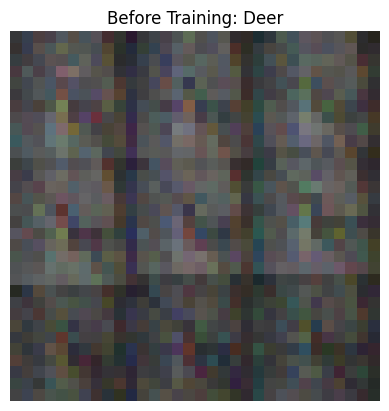

In [6]:
# 5. Display Image Before Training
i = 10

plt.imshow(X[i])
plt.title("Before Training: " + class_names[y[i]])
plt.axis("off")
plt.show()


In [7]:
# 6. Normalize Images
X = X / 255.0


In [8]:
# 7. Build Feedforward Neural Network
model = Sequential([
    Flatten(input_shape=(32, 32, 3)),
    Dense(128, activation='relu'),
    Dense(10, activation='softmax')
])

c:\Users\Vaishnavi\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\layers\reshaping\flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [9]:
# 8. Compile Model
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [10]:
# 9. Train Model
model.fit(X, y, epochs=5, batch_size=64)

Epoch 1/5
782/782 ━━━━━━━━━━━━━━━━━━━━ 9s 9ms/step - accuracy: 0.3055 - loss: 1.9371
Epoch 2/5
782/782 ━━━━━━━━━━━━━━━━━━━━ 7s 8ms/step - accuracy: 0.3685 - loss: 1.7797
Epoch 3/5
782/782 ━━━━━━━━━━━━━━━━━━━━ 7s 9ms/step - accuracy: 0.3842 - loss: 1.7270
Epoch 4/5
782/782 ━━━━━━━━━━━━━━━━━━━━ 7s 9ms/step - accuracy: 0.3959 - loss: 1.6990
Epoch 5/5
782/782 ━━━━━━━━━━━━━━━━━━━━ 8s 10ms/step - accuracy: 0.4042 - loss: 1.6792


In [11]:
# 10. Evaluate Model
loss, accuracy = model.evaluate(X, y)

print("Accuracy:", accuracy * 100, "%")

1563/1563 ━━━━━━━━━━━━━━━━━━━━ 11s 7ms/step - accuracy: 0.4130 - loss: 1.6501
Accuracy: 41.304001212120056 %


In [12]:
# 11. Predict Same Image After Training
prediction = model.predict(X[i:i+1], verbose=0)
predicted_class = np.argmax(prediction)

print("Actual Class:", class_names[y[i]])
print("Predicted Class:", class_names[predicted_class])


Actual Class: Deer
Predicted Class: Deer


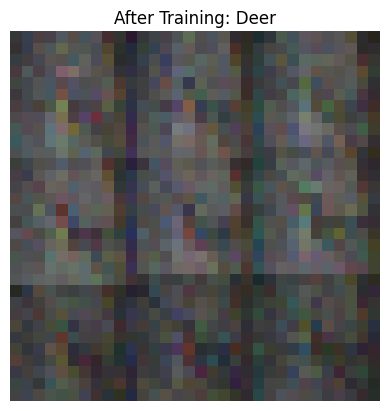

: 

In [ ]:
# 12. Display Same Image After Training
plt.imshow(X[i])
plt.title("After Training: " + class_names[predicted_class])
plt.axis("off")
plt.show()